## Лабораторная работа №1 | Вариант 4

Выполнил: Василянская Алёна М8О-314БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [67]:
arr = [1, 2, 0, 0, 4, 0]
arr = np.nonzero(arr)
arr

(array([0, 1, 4]),)

2. Создайте единичную матрицу размером 3х3

In [68]:
arr = np.eye(3)
arr

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [69]:
arr = np.tile(([0, 1], [1, 0]), (4, 4))
arr

array([[0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0]])

4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [70]:
arr = [0, 4, 4, 2, 1, 4, 8, 7, 10, 15]
arr = np.array(arr)
arr = arr[(arr < 3) | (arr > 8)]
arr

array([ 0,  2,  1, 10, 15])

5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [71]:
arr = np.random.random(10)
arr[np.argmax(arr)] = 0
arr

array([0.57622659, 0.4813364 , 0.84026677, 0.24028744, 0.62738188,
       0.10464561, 0.00814845, 0.65082368, 0.        , 0.56912891])

6. Как распечатать все значения в массиве?

In [72]:
arr = np.set_printoptions(threshold=np.inf)

7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [87]:
points = np.random.random((100, 2))
distances = np.sqrt(np.sum((points[:, np.newaxis, :] - points[np.newaxis, :, :]) ** 2, axis=2))
print(distances.shape)

(100, 100)


8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [75]:
arr = np.array([1.5, 2.7, 3.9], dtype=np.float32)
arr = arr.astype(np.int32)
print(arr, arr.dtype)

[1 2 3] int32


9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [76]:
text = """1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11"""
with open("data.txt", "w", encoding="utf-8") as file:
    file.write(text)
arr = np.genfromtxt("data.txt", delimiter=",", filling_values=0)
arr

array([[ 1.,  2.,  3.,  4.,  5.],
       [ 6.,  0.,  0.,  7.,  8.],
       [ 0.,  0.,  9., 10., 11.]])

10. Какой эквивалент enumerate для numpy массивов?

In [78]:
arr = np.array([[10, 20],[30, 40]])
for index, value in np.ndenumerate(arr):
    print(index, value)

(0, 0) 10
(0, 1) 20
(1, 0) 30
(1, 1) 40


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [12]:
import pandas as pd

In [79]:
# Load dataset here
df = pd.read_csv("russian-housing-market.csv")
df.head()

,id,timestamp,full_sq,life_sq,floor,max_floor,material,build_year,num_room,kitch_sq,state,product_type,sub_area,price_doc
0,1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,5850000
1,2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,6000000
2,3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,5700000
3,4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,13100000
4,5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,16331452


1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [36]:
df["life_sq"].isna().sum()

np.int64(6383)

2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

In [66]:
missing_before = df["life_sq"].isna().sum()
valid = df[df["life_sq"].notna() & df["full_sq"].notna() & (df["full_sq"] > 0) & (df["life_sq"] > 0) & (df["life_sq"] <= df["full_sq"])]
ratio = (valid["life_sq"] / valid["full_sq"]).median()
mask = df["life_sq"].isna() & df["full_sq"].notna()
df.loc[mask, "life_sq"] = df.loc[mask, "full_sq"] * ratio
missing_after = df["life_sq"].isna().sum()

print("Пропусков до замены:", missing_before)
print("Медианное отношение:", ratio)
print("Пропусков после замены:", missing_after)

Пропусков до замены: 6383
Медианное отношение: 0.6
Пропусков после замены: 0


Я заменила пропущенные значения, используя соотношение жилой площади к общей. Решила так сделать, потому что у квартир с большей общей площадью обычно больше и жилая площадь
Мы можем примерно рассчитать недостающие значения. Думаю, это хороший вариант, потому что он позволяет заполнить пропуски, не удаляя данные

3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [37]:
df["full_sq"].quantile([0.25, 0.50, 0.75])

0.25    38.0
0.50    49.0
0.75    63.0
Name: full_sq, dtype: float64

4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [ ]:
filtered = df[(df["full_sq"] >= 50) & (df["full_sq"] <= 70)]
filtered["price_doc"].mean()

np.float64(7243041.190994609)

5. Какая максимальная этажность здания представлена в датасете

In [42]:
df["max_floor"].max()

np.float64(117.0)

6. Выявите район с самым дорогим жильем

In [ ]:
district_prices = df.groupby("sub_area")["price_doc"].mean()
district_prices.idxmax()

'Hamovniki'

7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [44]:
mitino = df[df["sub_area"] == "Mitino"].copy()
mitino["price_per_sq"] = mitino["price_doc"] / mitino["full_sq"]
mitino["price_per_sq"].mean()

np.float64(171841.39999559196)

8. Посчитайте среднюю площадь комнаты в Бибирево

In [45]:
bibirevo = df[df["sub_area"] == "Bibirevo"].copy()
bibirevo["room_area"] = (bibirevo["life_sq"] / bibirevo["num_room"])
bibirevo.loc[bibirevo["num_room"] > 0, "room_area"].mean()

np.float64(15.980421686746988)

9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

In [89]:
floors = df[df["floor"].isin([1, 9])]
floors.groupby("floor")["price_doc"].mean()

floor
1.0    5.739380e+06
9.0    6.937583e+06
Name: price_doc, dtype: float64

Средняя цена квартир на 9-м этаже выше, чем на 1-м

10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [ ]:
filtered = df[(df["life_sq"] >= 60) & (df["num_room"] >= 3) & (df["floor"] >= 5)]
filtered["price_doc"].min()

np.int64(1000000)

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

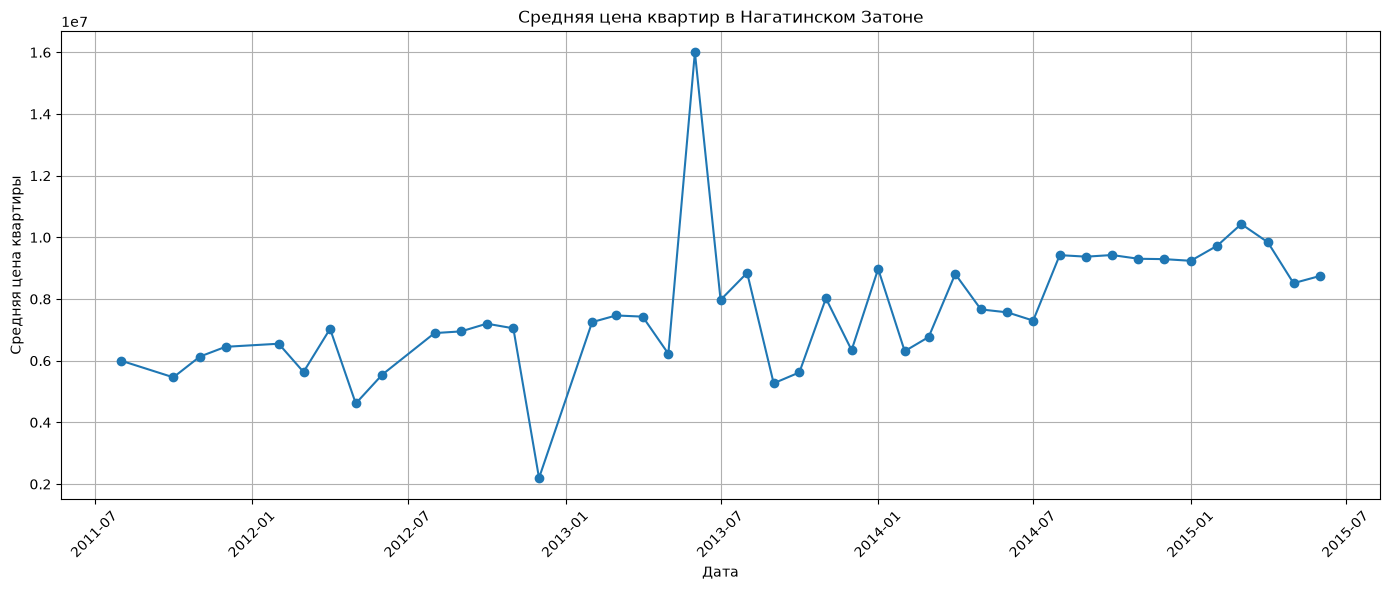

In [80]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

nag = df[df["sub_area"] == "Nagatinskij Zaton"].copy()
nag_monthly = nag.groupby(nag["timestamp"].dt.to_period("M"))["price_doc"].mean()
nag_monthly.index = nag_monthly.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(nag_monthly.index, nag_monthly.values, marker="o")
plt.title("Средняя цена квартир в Нагатинском Затоне")
plt.xlabel("Дата")
plt.ylabel("Средняя цена квартиры")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

График показывает, как менялась средняя стоимость квартир в Нагатинском Затоне с течением времени. По нему можно проследить рост и снижение цен каждое полугодие

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

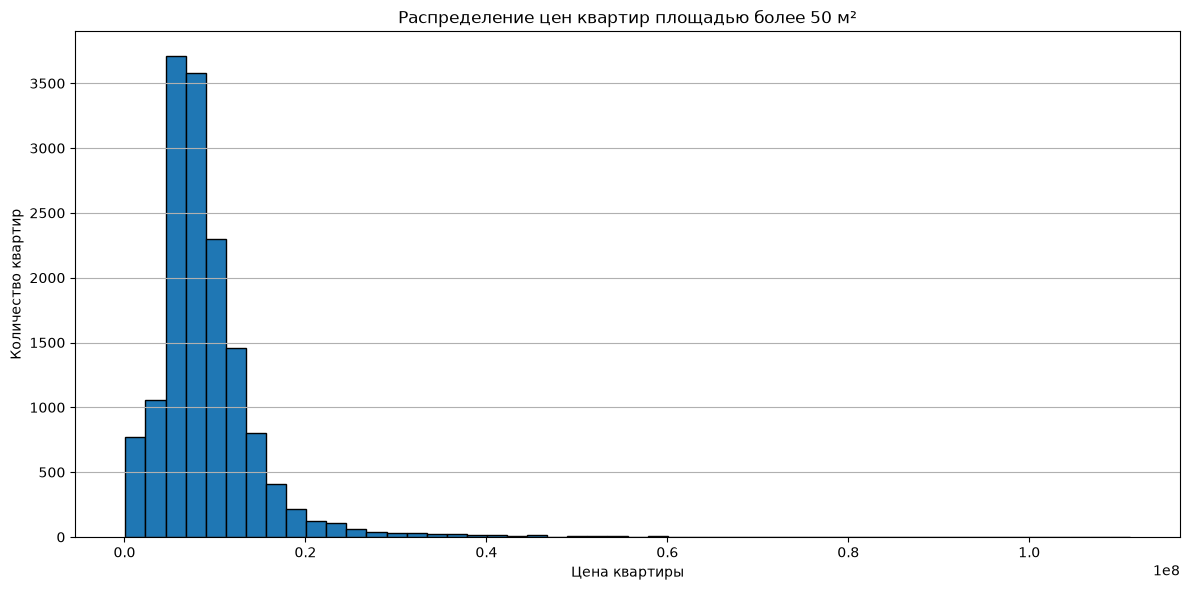

In [81]:
large_flats = df[df["full_sq"] > 50]

plt.figure(figsize=(12, 6))
plt.hist(large_flats["price_doc"].dropna(), bins=50, edgecolor="black")

plt.title("Распределение цен квартир площадью более 50 м²")
plt.xlabel("Цена квартиры")
plt.ylabel("Количество квартир")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Гистограмма показывает, сколько квартир с площадью более 50 м² продавалось в разных ценовых диапазонах. Она помогает понять, какие цены встречаются чаще всего

3. Визуализируйте количество проданных квартир в разных районах

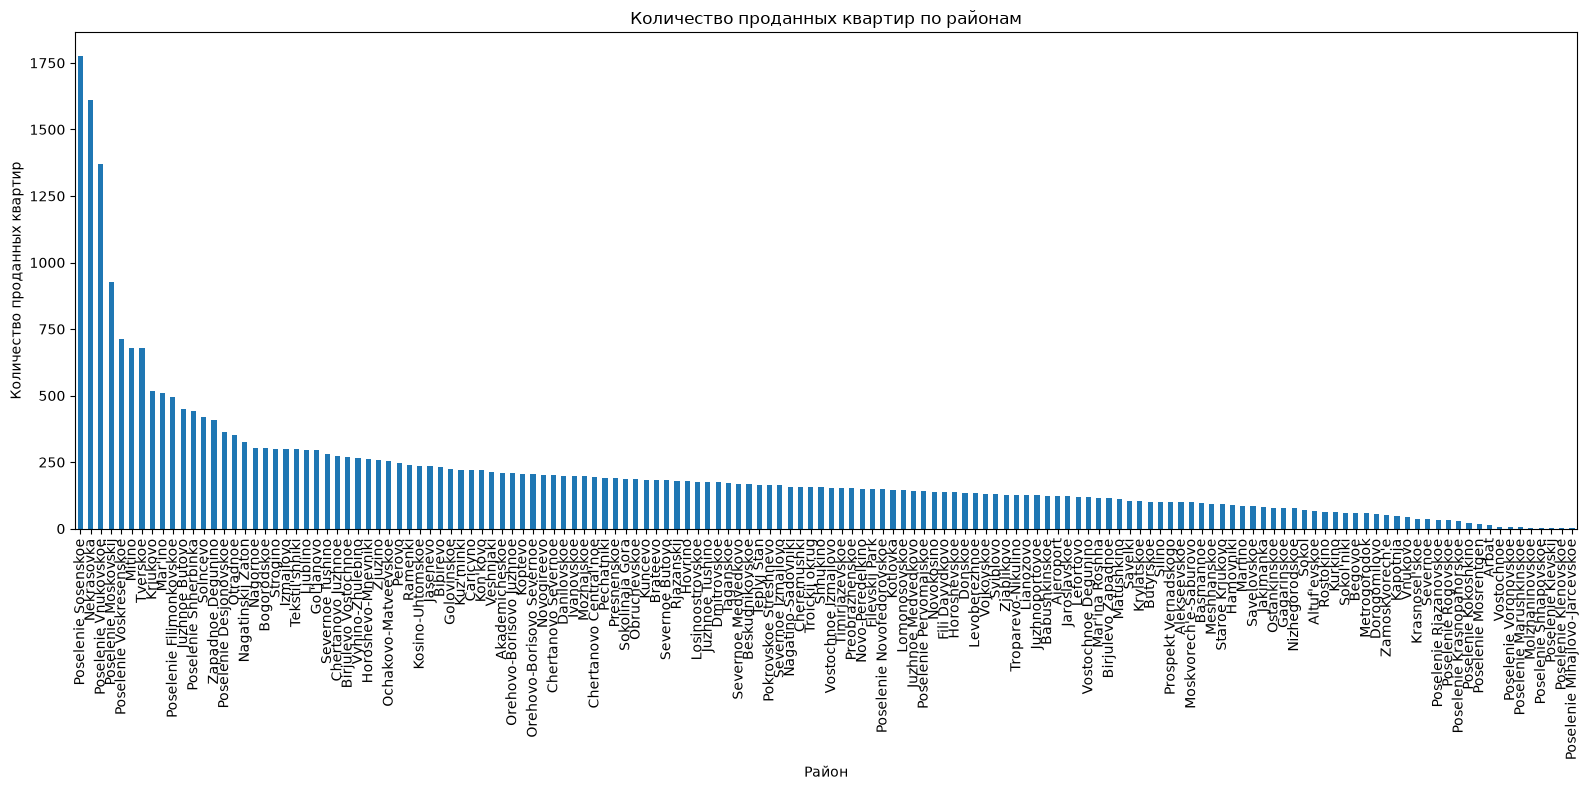

In [82]:
district_counts = df["sub_area"].value_counts()

plt.figure(figsize=(16, 8))
district_counts.plot(kind="bar")

plt.title("Количество проданных квартир по районам")
plt.xlabel("Район")
plt.ylabel("Количество проданных квартир")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

График показывает количество продаж в каждом районе. Он помогает увидеть как в зависимости от района меняется количество продаж

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

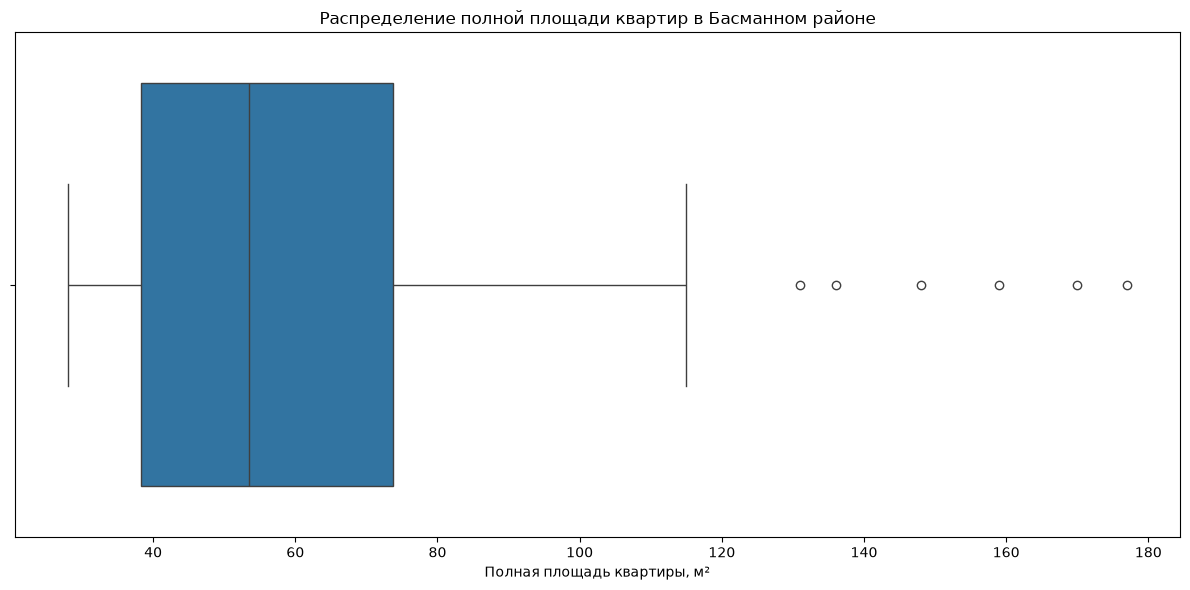

In [83]:
basman = df[df["sub_area"] == "Basmannoe"]
plt.figure(figsize=(12, 6))
sns.boxplot(x=basman["full_sq"].dropna())
plt.title("Распределение полной площади квартир в Басманном районе")
plt.xlabel("Полная площадь квартиры, м²")
plt.tight_layout()
plt.show()

Box plot показывает распределение общей площади квартир в Басманном районе. По нему можно увидеть типичную площадь квартир

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

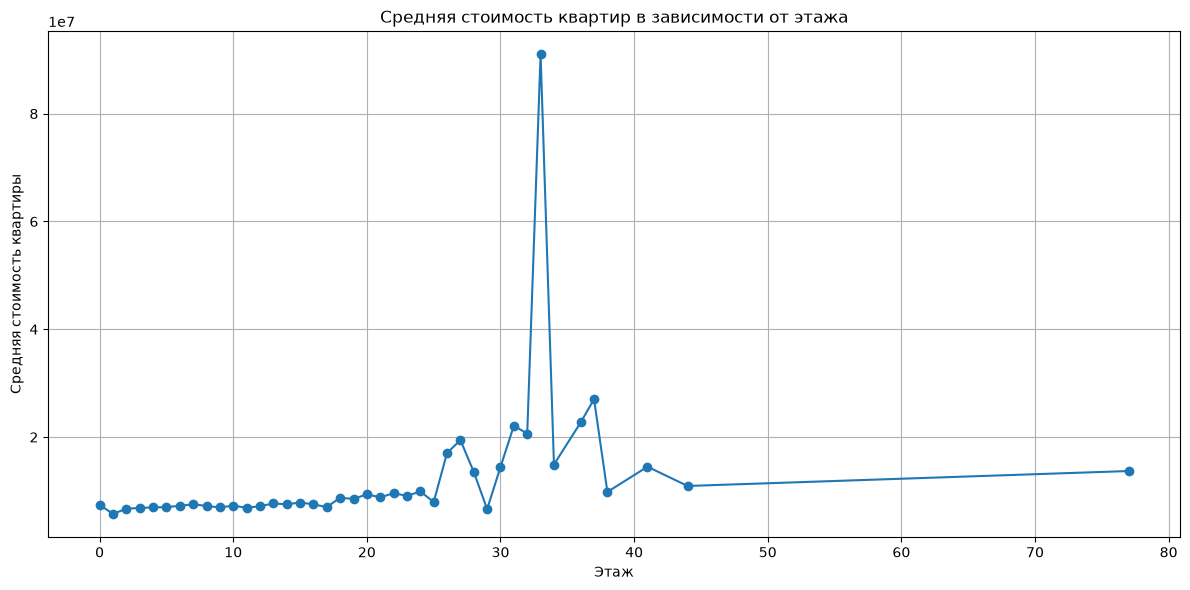

In [84]:
floor_prices = df.groupby("floor")["price_doc"].mean()

plt.figure(figsize=(12, 6))
plt.plot(floor_prices.index, floor_prices.values, marker="o")

plt.title("Средняя стоимость квартир в зависимости от этажа")
plt.xlabel("Этаж")
plt.ylabel("Средняя стоимость квартиры")
plt.grid(True)
plt.tight_layout()
plt.show()

График показывает, как меняется средняя цена квартиры в зависимости от этажа. Он помогает сравнить стоимость квартир на разных этажах

6. Покажите как меняется средняя площадь квартир в зависимости от района

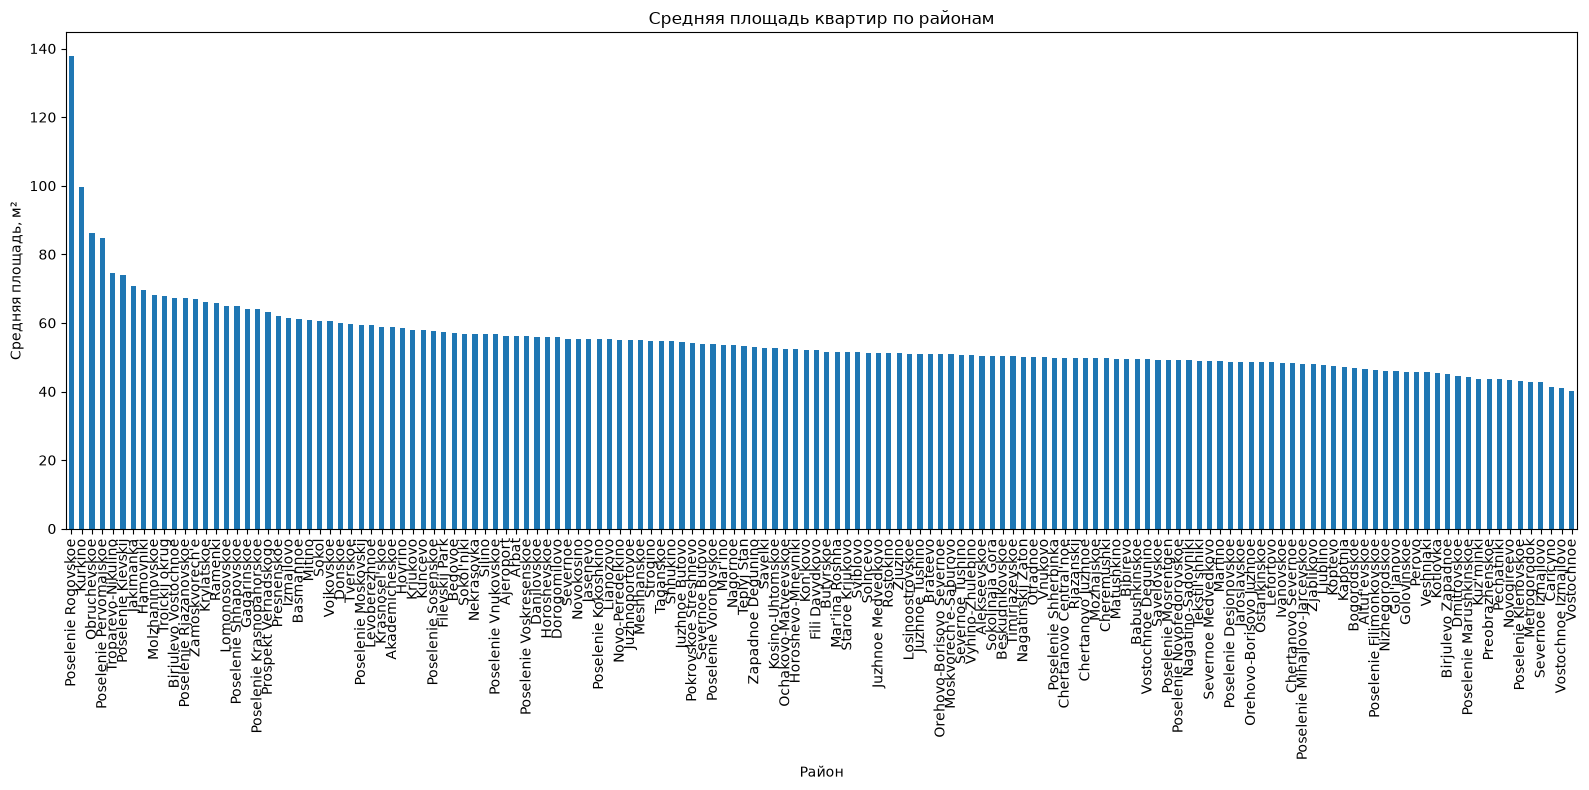

In [85]:
district_area = (df.groupby("sub_area")["full_sq"].mean().sort_values(ascending=False))

plt.figure(figsize=(16, 8))
district_area.plot(kind="bar")

plt.title("Средняя площадь квартир по районам")
plt.xlabel("Район")
plt.ylabel("Средняя площадь, м²")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

График показывает среднюю площадь квартир в каждом районе. По нему можно определить, в каких районах квартиры в среднем больше, а в каких меньше

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл

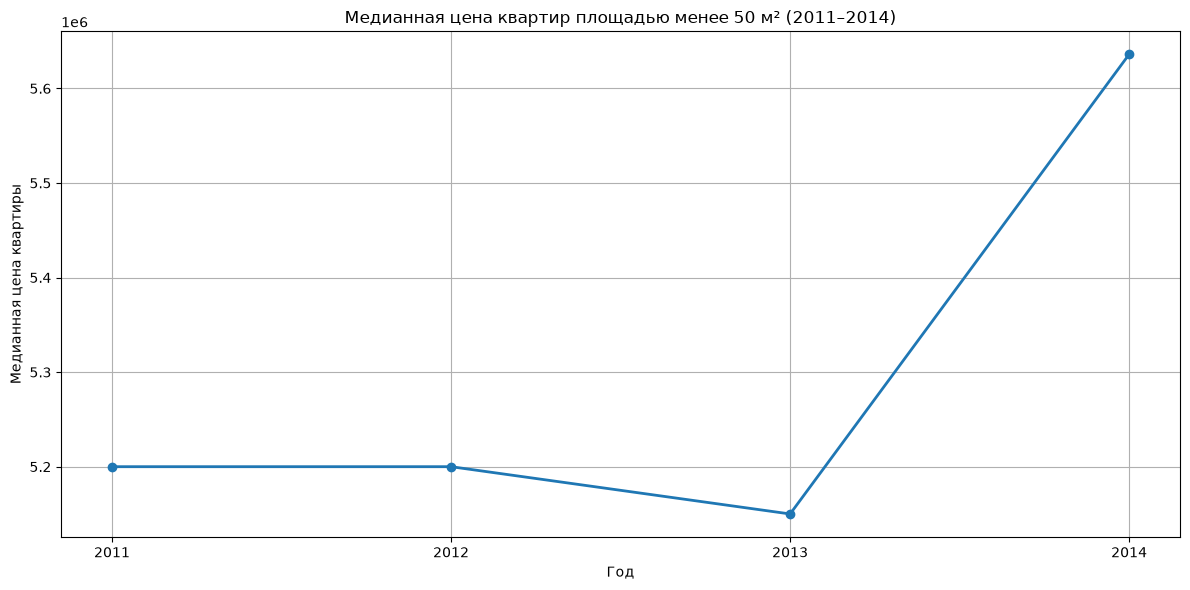

In [86]:
small_flats = df[(df["full_sq"] < 50) & (df["timestamp"].dt.year >= 2011) & (df["timestamp"].dt.year <= 2014)]

median_prices = (small_flats.groupby(small_flats["timestamp"].dt.year)["price_doc"].median())

plt.figure(figsize=(12, 6))
plt.plot(median_prices.index, median_prices.values, marker="o", linewidth=2)

plt.title("Медианная цена квартир площадью менее 50 м² (2011–2014)")
plt.xlabel("Год")
plt.ylabel("Медианная цена квартиры")
plt.xticks([2011, 2012, 2013, 2014])
plt.grid(True)
plt.tight_layout()
plt.show()

График показывает, как менялась медианная стоимость квартир площадью менее 50 кв. метров с 2011 по 2014 год. Он позволяет проследить изменение цен за этот период